# Integrantes del equipo
- Guillermo Arturo Pazo Purizaca

- Link Streamlit: https://vuelos-app-guille.streamlit.app/

# Nivel 1 · Plotly: análisis de correlación en el notebook
**Pregunta de negocio:** ¿qué hace que un vuelo llegue tarde: la antigüedad del avión, la hora de salida o el clima?

**Antes de empezar:** suba `vuelos_limpio.csv.gz` al panel **Archivos** de Colab.

**Paso 1.** Cargar los datos limpios. pandas lee directamente el archivo comprimido `.gz`.

In [1]:
import pandas as pd
import plotly.express as px

df = pd.read_csv("vuelos_limpio.csv.gz")
print(df.shape)
df.head()

(325802, 23)


,fecha,mes,dia_semana,hora_programada,franja_horaria,aerolinea,origen,destino,nombre_destino,distancia_km,...,temp_c,humedad,viento_kmh,lluvia_mm,visibilidad_km,llueve,retraso_salida,retraso_llegada,llego_tarde,rango_retraso
0,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,EWR,IAH,George Bush Intercontinental,2253.0,...,3.9,64.0,20.4,0.0,16.1,0,2.0,11.0,0,2. 0 a 14 min
1,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,LGA,IAH,George Bush Intercontinental,2278.0,...,4.4,55.0,24.1,0.0,16.1,0,4.0,20.0,1,3. 15 a 59 min
2,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),American,JFK,MIA,Miami Intl,1752.0,...,3.9,62.0,24.1,0.0,16.1,0,2.0,33.0,1,3. 15 a 59 min
3,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),JetBlue,JFK,BQN,BQN,2536.0,...,3.9,62.0,24.1,0.0,16.1,0,-1.0,-18.0,0,1. Llegó antes
4,2013-01-01,1,2. Martes,6,1. Mañana (5-11 h),Delta,LGA,ATL,Hartsfield Jackson Atlanta Intl,1226.0,...,4.4,55.0,25.9,0.0,16.1,0,-6.0,-25.0,0,1. Llegó antes


**Paso 2.** Elegir las variables numéricas y calcular la **matriz de correlación de Pearson**.

In [2]:
variables = ["retraso_llegada", "retraso_salida", "hora_programada", "mes", "distancia_km", "edad_avion",
             "asientos", "vuelos_misma_hora", "temp_c", "humedad", "viento_kmh", "lluvia_mm", "visibilidad_km"]

corr = df[variables].corr(method="pearson").round(2)

fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Matriz de correlación de Pearson · vuelos de Nueva York 2013")
fig.update_layout(width=900, height=800)
fig.show()

**Cómo leerla:** rojo = relación positiva (suben juntas); azul = negativa (una sube, la otra baja); blanco = sin relación lineal.
Pase el mouse sobre una celda: Plotly muestra el valor exacto. Eso es lo que **no** hace un gráfico estático.

**Paso 3.** Ordenar las variables según su correlación con el retraso de llegada.

In [3]:
con_retraso = corr["retraso_llegada"].drop("retraso_llegada").sort_values()
fig = px.bar(con_retraso, orientation="h", title="Correlación de cada variable con el retraso de llegada",
             labels={"value": "Correlación de Pearson", "index": ""}, color_discrete_sequence=["#2F5597"])
fig.update_layout(showlegend=False)
fig.show()

> **Pregunta 1.** ¿Qué variable se relaciona más con el retraso de llegada? ¿Sirve para tomar una decisión? ¿Y la edad del avión?
>
> **Respuesta.** El retraso de salida es la variable más asociada con el retraso de llegada (Pearson r = 0,915). Sirve como alerta una vez conocida la salida real, pero para decidir qué inversión hacer hay que examinar condiciones operativas previas. La edad presenta r = −0,018 entre vuelos con dato, una asociación lineal despreciable.

**Paso 4.** Repetir con **Spearman**, que mide relaciones que suben o bajan juntas aunque no sea en línea recta, y es menos sensible a los retrasos extremos de varias horas.

In [4]:
corr_s = df[variables].corr(method="spearman").round(2)
fig = px.imshow(corr_s, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Matriz de correlación de Spearman")
fig.update_layout(width=900, height=800)
fig.show()

**Paso 5.** La correlación con la hora es solo 0,17. Veamos el porcentaje de vuelos que llegan tarde según la franja horaria.

In [5]:
franjas = df.groupby("franja_horaria").agg(
    vuelos=("llego_tarde", "count"),
    pct_tarde=("llego_tarde", "mean"),
    retraso_promedio=("retraso_llegada", "mean"),
).round(3).reset_index()
franjas["pct_tarde"] = (franjas["pct_tarde"] * 100).round(1)
print(franjas)

fig = px.bar(franjas, x="franja_horaria", y="pct_tarde", text="pct_tarde",
             title="% de vuelos que llegan tarde según la hora de salida",
             labels={"franja_horaria": "", "pct_tarde": "% que llega tarde"},
             color="pct_tarde", color_continuous_scale="Blues")
fig.show()

          franja_horaria  vuelos  pct_tarde  retraso_promedio
0     1. Mañana (5-11 h)  128077       15.2            -1.848
1  2. Mediodía (12-15 h)   81043       25.6             8.198
2     3. Tarde (16-19 h)   86923       33.0            15.040
3     4. Noche (20-23 h)   29759       35.8            17.030


> **Pregunta 2.** Si el porcentaje de vuelos tarde se duplica de la mañana a la noche, ¿por qué la correlación es tan baja?
>
> **Respuesta.** Pearson (r = 0,174) mide la relación lineal entre la hora programada y los minutos de retraso por vuelo. Las tasas por franja comparan otra cantidad, la proporción de llegadas con 15 minutos de retraso o más. La dispersión dentro de cada franja puede ser alta aunque las tasas pasen de 15,2 % a 35,8 %.

**Paso 6.** ¿Y el clima? Comparemos los vuelos que salieron con lluvia y sin lluvia.

In [6]:
lluvia = df.groupby("llueve").agg(vuelos=("llego_tarde", "count"), pct_tarde=("llego_tarde", "mean")).reset_index()
lluvia["condicion"] = lluvia["llueve"].map({0: "Sin lluvia", 1: "Con lluvia"})
lluvia["pct_tarde"] = (lluvia["pct_tarde"] * 100).round(1)
print(lluvia)

fig = px.bar(lluvia, x="condicion", y="pct_tarde", text="pct_tarde", color="condicion",
             color_discrete_map={"Sin lluvia": "#4472C4", "Con lluvia": "#12366B"},
             title="% de vuelos que llegan tarde con y sin lluvia",
             labels={"condicion": "", "pct_tarde": "% que llega tarde"})
fig.update_layout(showlegend=False)
fig.show()

   llueve  vuelos  pct_tarde   condicion
0       0  304877       22.8  Sin lluvia
1       1   20925       48.6  Con lluvia


> **Pregunta 3.** La lluvia duplica el porcentaje de vuelos tarde. ¿Por qué entonces no sería la mejor inversión?
>
> **Respuesta.** La tasa sube de 22,8 % a 48,6 %, pero solo 20.925 vuelos (6,4 %) salieron con lluvia. Para escoger una inversión también importan los vuelos que se podrían beneficiar, el costo y el efecto que tendría la medida.

**Paso 7.** Cada punto es un **día del año**: ¿los días con más lluvia tienen más vuelos tarde?

In [7]:
dias = df.groupby("fecha").agg(pct_lluvia=("llueve", "mean"), pct_tarde=("llego_tarde", "mean"),
                               vuelos=("llego_tarde", "count")).reset_index()
dias["pct_lluvia"] *= 100
dias["pct_tarde"] *= 100
fig = px.scatter(dias, x="pct_lluvia", y="pct_tarde", size="vuelos", hover_data=["fecha"],
                 color_discrete_sequence=["#2F5597"],
                 title="Días del año: % de vuelos con lluvia frente a % de vuelos tarde",
                 labels={"pct_lluvia": "% de vuelos que salieron con lluvia", "pct_tarde": "% de vuelos tarde"})
import numpy as np

pendiente, intercepto = np.polyfit(dias["pct_lluvia"], dias["pct_tarde"], 1)
extremos = [dias["pct_lluvia"].min(), dias["pct_lluvia"].max()]
fig.add_scatter(x=extremos, y=[pendiente * x + intercepto for x in extremos],
                mode="lines", name="Regresión lineal")
fig.show()
print("Correlación por día:", round(dias["pct_lluvia"].corr(dias["pct_tarde"]), 2))

Correlación por día: 0.53


> **Pregunta 4.** Por vuelo, la correlación de la lluvia con el retraso es 0,11; por día es 0,53. ¿Cuál es la correcta?
>
> **Respuesta.** Ambas cifras describen análisis distintos. El 0,11 relaciona milímetros de lluvia con minutos de retraso por vuelo. El 0,53 compara el porcentaje diario de vuelos con lluvia y el porcentaje diario de llegadas tardías. Al agrupar cambia la unidad, cambian las variables y se atenúa la variabilidad entre vuelos.

**Paso 8.** ¿Qué aerolíneas llegan tarde con más frecuencia?

In [8]:
aero = df.groupby("aerolinea").agg(vuelos=("llego_tarde", "count"), pct_tarde=("llego_tarde", "mean")).reset_index()
aero["pct_tarde"] = (aero["pct_tarde"] * 100).round(1)
aero = aero.sort_values("pct_tarde", ascending=False)
fig = px.bar(aero, x="aerolinea", y="pct_tarde", hover_data=["vuelos"], color_discrete_sequence=["#2F5597"],
             title="% de vuelos que llegan tarde por aerolínea",
             labels={"aerolinea": "", "pct_tarde": "% que llega tarde"})
fig.show()

**Paso 9.** Compartir el gráfico: Plotly puede guardarlo como una página HTML interactiva que se abre en cualquier navegador.

In [9]:
fig_matriz = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                       title="Matriz de correlación · vuelos")
fig_matriz.write_html("matriz_correlacion.html")
print("Guardado: matriz_correlacion.html (descárguelo desde el panel Archivos)")

Guardado: matriz_correlacion.html (descárguelo desde el panel Archivos)


## Conclusiones

1. ¿Qué variable **no** explica los retrasos?
- La edad del avión muestra una asociación lineal prácticamente nula con el retraso de llegada (Pearson r = −0,02).

2. ¿Qué variable sí los explica y con qué cifra lo demuestran?
- El retraso de salida es la variable que más se relaciona con el retraso de llegada (Pearson r = 0,92). Esta relación permite activar alertas operativas cuando ya se conoce la demora de salida.

3. ¿Qué papel tiene el clima?
- La lluvia y la baja visibilidad se asocian con una mayor proporción de llegadas tardías. El 48,6 % de los vuelos que salieron con lluvia llegó tarde, frente al 22,8 % de los que salieron sin lluvia.

4. ¿Qué limitación tiene entregar este análisis en un notebook?
- Aunque los gráficos son interactivos, para cambiar el subconjunto de vuelos y recalcular los indicadores hay que editar y volver a ejecutar el código. Esto dificulta la exploración para quienes no programan.
-----------------
La edad del avión muestra una asociación prácticamente nula con los minutos de retraso.
El retraso de salida muestra la mayor asociación y sirve para alertas operativas.

La tasa de llegadas tardías aumenta a lo largo del día. La lluvia y la baja visibilidad también coinciden con tasas más altas.

ExpressJet (32,0 %), Envoy (27,9 %), JetBlue (26,9 %), Southwest (25,6 %), Endeavor (25,6 %) y Otras (25,1 %) están por encima del promedio general (24,4 %). United, American, Delta y US Airways están por debajo.

En el notebook, cambiar el subconjunto requiere editar y ejecutar código. Se propone probar una reprogramación selectiva de vuelos de tarde y noche.

## Nivel 2 · Indicadores con los filtros de Streamlit - Explorar con la app

| Filtro | Vuelos | % tarde | Retraso promedio | Correlación hora–retraso |
|---|---:|---:|---:|---:|
| Sin filtros, Pearson | 325.802 | 24,4 % | 6,9 min | 0,17 |
| EWR, Pearson | 116.487 | 26,3 % | 9,1 min | 0,20 |
| ExpressJet, Pearson | 50.863 | 32,0 % | 15,8 min | 0,20 |
| Delta, Pearson | 47.464 | 19,0 % | 1,6 min | 0,13 |
| Delta, Spearman | 47.464 | 19,0 % | 1,6 min | 0,08 |

**Pregunta 5.** ExpressJet presenta una asociación hora–retraso mayor que Delta. Las compañías pueden tener mezclas distintas de rutas, aeropuertos, horarios y exposición al clima. Conviene estudiar la reprogramación por aerolínea y ruta, controlando esos factores.

**Pregunta 6.** Los tramos de edad van del 21,4 % al 27,0 %, sin un aumento sostenido con la edad. Hay 53.264 vuelos sin edad registrada. La visibilidad presenta un gradiente más marcado: llega tarde el 48,1 % en el tramo de menor visibilidad y el 22,8 % en el de mayor visibilidad. Esto coincide con la diferencia en magnitud de Pearson (−0,02 para edad y −0,14 para visibilidad).

**Pregunta 7.** El gerente puede combinar filtros, cambiar el método de correlación, comparar tramos y descargar los datos del subconjunto. Las vistas siguen siendo descriptivas y se basan en vuelos completados de Nueva York en 2013.


## Nivel 3 · Power BI
Usamos `vuelos_powerbi_liviano.csv`, una selección de diez columnas de los mismos 325.802 vuelos analizados en Plotly y Streamlit. La consulta convierte los números con configuración regional `en-US`, que reconoce el punto decimal del CSV.

**Pregunta 8. ¿Qué diferencia hay entre una medida (como «% Llegadas
tarde») y una columna calculada (como «Clima»)? ¿Por qué la correlación debe ser una medida y no
una columna?**

La columna calculada **Clima** asigna un valor a cada vuelo cuando se procesa el modelo. Ese valor se puede usar para agrupar o filtrar. Una medida devuelve un resultado agregado para el conjunto de filas visible en cada visual. La correlación necesita pares de hora y retraso de varios vuelos. Al definirla como medida, Pearson se recalcula al filtrar por origen, mes o aerolínea.

**Pregunta 9. ¿Los valores de Power BI coinciden con los de la app de
Streamlit para los mismos filtros? ¿Por qué deberían coincidir?**

Se espera que coincidan cuando el subconjunto y el método sean iguales. Verifiqué que las diez columnas del CSV liviano coinciden fila por fila con las del dataset de Streamlit. Ambos cálculos cuentan vuelos completados, promedian el mismo indicador de retraso de 15 minutos y aplican Pearson a la hora programada y el retraso de llegada.

| Filtro | Vuelos | Llegadas tardías | Retraso medio | Vuelos con lluvia | Pearson hora–retraso |
| --- | ---: | ---: | ---: | ---: | ---: |
| Sin filtros | 325.802 | 24,4 % | 6,9 min | 6,4 % | 0,17 |
| EWR | 116.487 | 26,3 % | 9,1 min | 6,7 % | 0,20 |
| ExpressJet | 50.863 | 32,0 % | 15,8 min | 6,0 % | 0,20 |
| ExpressJet + EWR | 41.352 | 33,2 % | 17,0 min | 6,1 % | 0,22 |

Los valores de control se calcularon directamente del CSV. El caso combinado se compara con Streamlit seleccionando ambos filtros y el método Pearson.

**Pregunta 10. En el gráfico de dispersión, cada punto es un día. ¿Qué
relación se ve entre la lluvia y los retrasos? ¿Por qué se ve más fuerte que en la matriz de
correlación por vuelo?**

En los días con una mayor proporción de salidas bajo lluvia también tiende a aumentar la proporción de llegadas tardías. La correlación entre esos porcentajes diarios es **r = 0,53**. El **r = 0,11** de la matriz compara milímetros de lluvia con minutos de retraso por vuelo. Al cambiar la unidad a días y usar proporciones se reduce parte de la variabilidad individual. Las dos cifras describen relaciones distintas.


### Captura del tablero
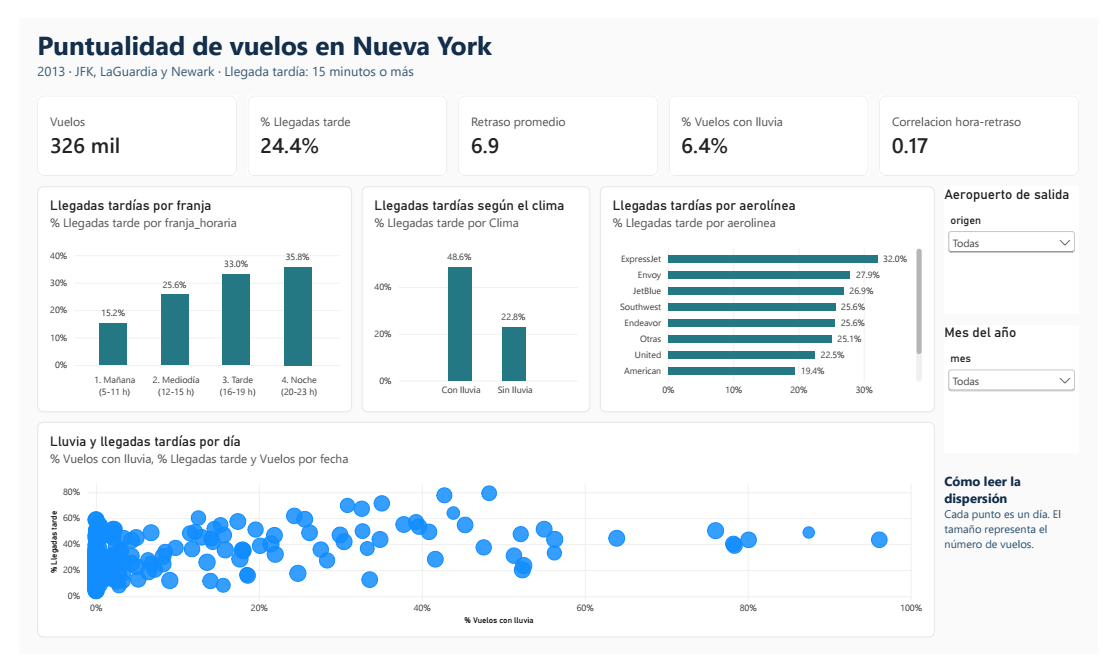

## Comparación de los tres niveles

| Aspecto | Plotly | Streamlit | Power BI |
| --- | --- | --- | --- |
| ¿Para quién es? | Analista de datos. | Equipo de operaciones y otras áreas. | Gerencia y usuarios de negocio. |
| ¿Qué puede hacer el usuario? | Explorar gráficos, reproducir cálculos y modificar el análisis desde Python. | Combinar filtros, alternar entre Pearson y Spearman y descargar los datos filtrados. | Cruzar visuales, segmentar el informe y recalcular las medidas DAX. |
| ¿Cómo se comparte? | Notebook de Colab, archivo `.ipynb` o gráfico en HTML. | Enlace a la aplicación web. | Archivo `.pbix` o informe publicado en Power BI Service. |
| Principal ventaja | Permite revisar cómo se obtuvo cada resultado. | Permite explorar los resultados desde un navegador. | Las medidas se recalculan en las distintas vistas cuando cambia un filtro. |
| Principal limitación | Cambiar el análisis requiere editar y ejecutar código. | Los usuarios exploran las vistas y filtros definidos en la app. | El archivo editable requiere Power BI Desktop. Compartirlo en línea depende del acceso a Power BI Service. |

[Aplicación de Streamlit](https://vuelos-app-guille.streamlit.app/)


## Respuesta al gerente de operaciones

1. **Recomendación.** Invertir en un piloto de reprogramación de vuelos de tarde y noche. Empezaría por las rutas de esas franjas con más llegadas tardías y mediría el costo por retraso evitado.
2. **Evidencia.** En Plotly, el **15,2 %** de los vuelos de la mañana llegó tarde, frente al **33,0 %** de los de la tarde y el **35,8 %** de los de la noche. En Streamlit, ExpressJet registró **32,0 %** de llegadas tardías. Los indicadores calculados para el tablero Power BI muestran **24,4 %** de llegadas tardías y una correlación hora–retraso de **0,17** en los **325.802** vuelos.
3. **Otras inversiones.** La renovación de flota queda fuera de esta primera inversión porque la correlación entre edad y retraso de llegada fue **−0,02** entre los vuelos con edad registrada. La inversión en operaciones con mal tiempo queda como segunda prioridad. Con lluvia llegó tarde el **48,6 %**, frente al **22,8 %** sin lluvia, y el **6,4 %** de las salidas estuvo expuesto a lluvia.
4. **Límite del análisis.** Los datos permiten observar asociaciones. La estimación del efecto de reprogramar requiere un piloto con vuelos comparables. La limpieza excluyó vuelos sin salida o sin retraso de llegada registrado, y faltó la edad de la aeronave en **53.264** vuelos. Los resultados describen vuelos completados en Nueva York durante 2013.
5. **Hipótesis inicial.** Los resultados respaldan priorizar el horario como hipótesis de trabajo. La tasa de llegadas tardías aumentó de la mañana a la noche. Para saber cuánto cambiaría con una reprogramación, compararía vuelos similares por ruta, aerolínea, aeropuerto y clima.
6. **Formato para gerencia.** Presentaría el tablero de Power BI. Permite ver los indicadores generales y pasar a un aeropuerto o mes concreto para identificar dónde probar y seguir la medida.
